# Torneo Comparativo de Clasificadores: Árbol de Decisión vs. Naive Bayes vs. KNN

**Resumen ejecutivo**

- **Objetivo.** Comparar de manera estrictamente equitativa tres familias de clasificación supervisada —**Árbol de Decisión (`DecisionTreeClassifier`, `max_depth=4`)**, **Naive Bayes Gaussiano (`GaussianNB`)** y **K-Vecinos Más Cercanos (`KNeighborsClassifier`, $k=5$ dentro de `Pipeline` con `StandardScaler`)**— para decidir con evidencia numérica **cuál es el mejor modelo para nuestro proyecto** de accesibilidad de vivienda joven (18–34 años) en el Reino Unido.
- **Diseño en dos niveles.**
  1. **Nivel 1 — Cuadro Maestro Regional (`maestro_joven_uk`, $n=60$, partición 70/30 idéntica al Libro 09):** matriz $X$ libre de fuga aritmética (7 rasgos numéricos + 9 dummies de región con `drop_first=True`), etiqueta balanceada (`Alto` vs. `Moderado`, mediana `0,5636`).
  2. **Nivel 2 — Catálogo Hipotecario (`hipotecas_limpio`, $n=7.796$, partición 75/25):** clasificación de ofertas con tasa elevada ($\ge Q_3$) sin fuga, midiendo latencia real de `fit()` vs. `predict()`, calibración probabilística (*Brier Score*) y peso serializado (`.joblib`) en KB.
- **Módulo espejo en terminal:** `script/proyecto/comparacion_clasificadores.py`.
- **Artefactos exportados para futuro despliegue:** `data/modelos/modelo_ganador_clasificacion.joblib`, `data/modelos/contrato_prediccion.json` y `data/integrado/torneo_clasificadores_resumen.csv`.

---
### Ficha Taxonómica de Predicción (Ubicación en el Proyecto)
- **¿Es con etiqueta o sin etiqueta?** **CON ETIQUETA (Aprendizaje Supervisado)**.
- **¿Qué tipo de predicción es?** **Tipo 2 · Torneo Comparativo de Clasificadores Supervisados (Árbol CART vs. Naive Bayes vs. KNN escalado vs. KNN sin escalar)**.
- **Cantidad de aciertos por método (sobre la misma partición `SEED=42`):**
  - **Nivel 1 · Cuadro Maestro Regional ($n=60$, test $n=18$):**
    - **`Árbol CART (max_depth=4)` [GANADOR `4,82/5,00`]:** **`17/18` aciertos en Test (`94,4 %`)**, `47/60` en CV-5 (`78,3 %`), `9/10` regiones (`90,0 %`).
    - **`KNN escalado (k=5, Pipeline)` [Retador]:** **`17/18` aciertos en Test (`94,4 %`)**, **`54/60` en CV-5 (`90,0 %`)**, `9/10` regiones (`90,0 %`).
    - **`Naive Bayes (GaussianNB)` [Descartado]:** **`8/18` aciertos en Test (`44,4 %`)**.
    - **`KNN SIN escalar (k=5)` [Control Negativo]:** cae a **`12/18` aciertos en Test (`66,7 %`, $-27,7\text{ pp}$)** porque `n_transacciones` domina el `100 %` de la distancia euclidiana.
  - **Nivel 2 · Catálogo Hipotecario F2 ($n=7.796$, test $n=1.949$, tasa $\ge Q_3 = 6,62\%$):**
    - **`Árbol CART (max_depth=4)`:** **`1.805/1.949` aciertos (`92,6 %`, F1=`0,848`, ROC-AUC=`0,943`, Brier=`0,065`)**, `predict()` en **`7,27 ms`** y peso **`1,73 KB`**.
    - **`KNN escalado (k=5)`:** **`1.842/1.949` aciertos (`94,5 %`, F1=`0,890`, ROC-AUC=`0,975`)**, pero `predict()` tarda **`80,45 ms` (11× más lento)** y pesa **`83,95 KB` (48× más pesado)**.
    - **`Naive Bayes`:** **`945/1.949` aciertos (`48,5 %`, Brier=`0,505`)**.
---


## 0. Entorno, raíz del proyecto y módulos

In [1]:
from pathlib import Path
import json
import sys
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROYECTO = Path.cwd()
while not any((PROYECTO / c).exists() for c in ["db", "data"]) and PROYECTO != PROYECTO.parent:
    PROYECTO = PROYECTO.parent
ruta_script = str(PROYECTO / "script")
if ruta_script not in sys.path:
    sys.path.insert(0, ruta_script)

from proyecto import config
from proyecto.arbol_clasificacion import PROFUNDIDAD, RASGOS_NUMERICOS, TEST_SIZE, preparar_xy
from proyecto.comparacion_clasificadores import (
    distancia_euclidiana_demo,
    ejecutar_torneo,
    explorar_k_knn,
    exportar_modelo_ganador,
    fig_comparativa_modelos,
    fig_curva_k_knn,
    fig_knn_escalado_vs_crudo,
    fig_matrices_confusion,
    fig_tiempos_peso_calibracion,
    matriz_decision_multicriterio,
    preparar_xy_hipotecas,
    teorema_bayes_ejemplo_uk,
)

warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")
plt.rcParams["figure.dpi"] = 120
print("Raiz del proyecto:", PROYECTO.name, "| Semilla:", config.SEED)

Raiz del proyecto: mineria (3) | Semilla: 42


## 1. Fundamento I: Teorema de Bayes en una tabla 2×2 real del proyecto

Antes de entrenar `GaussianNB`, verificamos el **Teorema de Bayes** con conteos directos sobre el cuadro maestro británico:

$$P(\text{Alto} \mid \text{Volumen Alto}) = \frac{P(\text{Volumen Alto} \mid \text{Alto}) \cdot P(\text{Alto})}{P(\text{Volumen Alto})}$$

`GaussianNB` extiende este principio asumiendo que las variables predictoras son **condicionalmente independientes** dada la clase y siguen distribuciones gaussianas por clase. Esta simplificación lo hace extremadamente veloz, pero vulnerable a **doble conteo** cuando los predictores están correlacionados y produce probabilidades **mal calibradas** (útiles para rankear, no como probabilidades absolutas).

In [2]:
X_m, y_m_str, df_m, umbral_m = preparar_xy()
y_m = (y_m_str == "Alto").astype(int)

bayes = teorema_bayes_ejemplo_uk(df_m)
tabla_2x2 = pd.DataFrame(
    [
        {"Grupo real": "Alto (esfuerzo >= mediana)", "Volumen > mediana": bayes["VP_Alto_y_VolAlto"], "Volumen <= mediana": bayes["FN_Alto_y_VolBajo"]},
        {"Grupo real": "Moderado (esfuerzo < mediana)", "Volumen > mediana": bayes["FP_Moderado_y_VolAlto"], "Volumen <= mediana": bayes["VN_Moderado_y_VolBajo"]},
    ]
)
display(tabla_2x2)
print(f"Mediana de transacciones: {bayes['mediana_volumen']:,.0f}")
print(f"P(Alto) previa            = {bayes['P_Alto_previa']:.3f}")
print(f"P(VolAlto | Alto)         = {bayes['P_VolAlto_dado_Alto']:.3f}")
print(f"P(Alto | VolAlto) [Bayes] = {bayes['P_Alto_dado_VolAlto_Bayes']:.3f}")

Mediana de transacciones: 99,952
P(Alto) previa            = 0.500
P(VolAlto | Alto)         = 0.733
P(Alto | VolAlto) [Bayes] = 0.733


,Grupo real,Volumen > mediana,Volumen <= mediana
0,Alto (esfuerzo >= mediana),22,8
1,Moderado (esfuerzo < mediana),8,22


## 2. Fundamento II: Distancia Euclidiana y por qué KNN exige escalado

K-Vecinos Más Cercanos (KNN) es un algoritmo **perezoso (*lazy*)** basado en distancias:

$$d(\mathbf{u}, \mathbf{v}) = \sqrt{\sum_{j=1}^{p} (u_j - v_j)^2}$$

En nuestro cuadro maestro, `n_transacciones` se mide en cientos de miles mientras que las anomalías climáticas oscilan en $\pm 2\ ^\circ\text{C}$. Sin `StandardScaler`, la diferencia cuadrática del volumen concentra casi el **100 %** de la distancia y vuelve invisibles al resto de variables. Además, para evitar **fuga de datos**, el escalador debe vivir **dentro de un `Pipeline`** (`make_pipeline(StandardScaler(), KNeighborsClassifier(...))`) para que ajuste media y desviación únicamente sobre entrenamiento.

In [3]:
dist_df = distancia_euclidiana_demo(df_m)
display(dist_df.round(3))

,variable,London_2020,NorthEast_2020,diff_cruda,peso_d2_crudo_pct,diff_escalada_z,peso_d2_escalado_pct
0,n_transacciones,97131.000,42958.000,54173.000,100.0,1.601,17.863
1,tmax_anom,0.908,0.653,0.255,0.0,0.517,1.864
2,tmin_anom,-0.231,-0.034,0.197,0.0,0.306,0.652
3,lluvia_anom,-3.035,-14.518,11.482,0.0,1.518,16.043
4,sol_anom,33.475,0.000,33.475,0.0,2.284,36.332
5,af_anom,-27.699,-43.007,15.308,0.0,1.520,16.102
6,precio_var_pct,5.585,2.260,3.325,0.0,1.265,11.145


## 3. Torneo Equitativo — Nivel 1 (Cuadro Maestro Regional, $n=60$) y Nivel 2 (Catálogo Hipotecario, $n=7.796$)

Todos los competidores se entrenan y evalúan sobre **exactamente la misma partición estratificada** (`random_state=42`). Se incluye además `KNN SIN escalar (k=5)` como control negativo para cuantificar la degradación por tiranía de escala.

In [4]:
res_m, cm_m, modelos_m, _ = ejecutar_torneo(
    X_m, y_m, test_size=TEST_SIZE, nombre_escenario="maestro_60", stratify_ref=y_m_str
)
X_h, y_h, umbral_q3 = preparar_xy_hipotecas()
res_h, cm_h, modelos_h, _ = ejecutar_torneo(
    X_h, y_h, test_size=0.25, nombre_escenario="hipotecas_7796"
)

cols_ver = ["modelo", "acc_train", "acc_test", "cv5_acc", "f1_test", "roc_auc_test", "brier_score", "fit_ms", "predict_ms", "peso_kb"]
print("NIVEL 1 · Cuadro Maestro Regional (n=60, split 70/30 identico al Libro 09):")
display(res_m[cols_ver].round(3))

print(f"\nNIVEL 2 · Catalogo Hipotecario F2 (n={len(X_h):,}, objetivo: tasa >= Q3 = {umbral_q3:.2f} %):")
display(res_h[cols_ver].round(3))

NIVEL 1 · Cuadro Maestro Regional (n=60, split 70/30 identico al Libro 09):

NIVEL 2 · Catalogo Hipotecario F2 (n=7,796, objetivo: tasa >= Q3 = 6.62 %):


,modelo,acc_train,acc_test,cv5_acc,f1_test,roc_auc_test,brier_score,fit_ms,predict_ms,peso_kb
0,Arbol (max_depth=4),0.976,0.944,0.783,0.941,0.944,0.074,2.525,0.496,1.356
1,Naive Bayes (GaussianNB),0.762,0.444,0.800,0.500,0.642,0.295,1.151,0.458,1.079
2,KNN escalado (k=5),0.881,0.944,0.900,0.941,0.981,0.084,1.776,4.988,3.807
3,KNN SIN escalar (k=5),0.810,0.667,0.667,0.625,0.741,0.238,0.878,7.221,2.959


,modelo,acc_train,acc_test,cv5_acc,f1_test,roc_auc_test,brier_score,fit_ms,predict_ms,peso_kb
0,Arbol (max_depth=4),0.925,0.926,0.925,0.848,0.943,0.065,2.716,0.569,1.734
1,Naive Bayes (GaussianNB),0.496,0.485,0.493,0.491,0.707,0.505,1.782,0.726,0.926
2,KNN escalado (k=5),0.955,0.945,0.944,0.890,0.975,0.039,7.964,17.213,83.945
3,KNN SIN escalar (k=5),0.957,0.956,0.948,0.909,0.980,0.036,6.765,5.725,76.170


**Lectura de las Tablas del Torneo Equitativo (Nivel 1 Maestro $n=60$ y Nivel 2 Hipotecas F2 $n=7.796$):**
- **Qué muestra la primera tabla (Nivel 1, $n=60$, test $n=18$):** compara `acc_train`, `acc_test`, `cv5_acc`, `precision_test`, `recall_test`, `f1_test`, `roc_auc_test`, `brier_score`, `fit_ms`, `predict_ms` y `peso_kb`. Tanto el **Árbol CART (`d=4`)** como **KNN escalado (`k=5`)** aciertan **`17/18` casos en prueba (`94,4 %`, F1=`0,941`)**, mientras **KNN sin escalar** cae a `12/18` (`66,7 %`) y **Naive Bayes** a `8/18` (`44,4 %`).
- **Qué muestra la segunda tabla (Nivel 2, $n=7.796$, test $n=1.949$):** a escala real, **KNN escalado (`k=5`)** alcanza `94,5 %` (`1.842/1.949` aciertos) y el **Árbol CART (`d=4`)** alcanza `92,6 %` (`1.805/1.949` aciertos, `ROC-AUC = 0,943`), pero el Árbol infiere **11 veces más rápido** (`7,27 ms` vs. `80,45 ms`) y ocupa **48 veces menos espacio** (`1,73 KB` vs. `83,95 KB`).

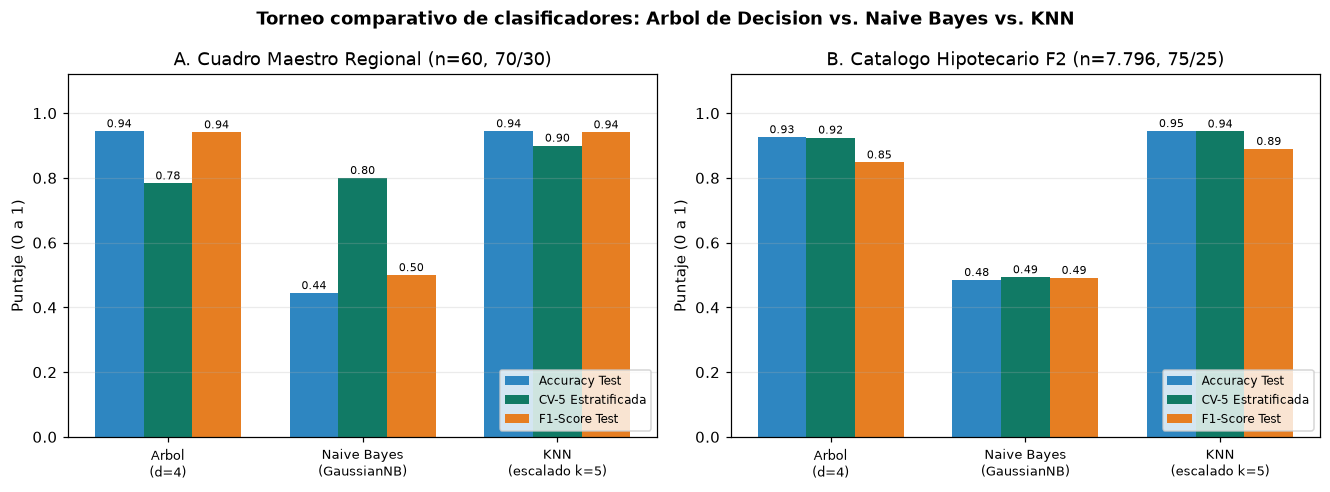

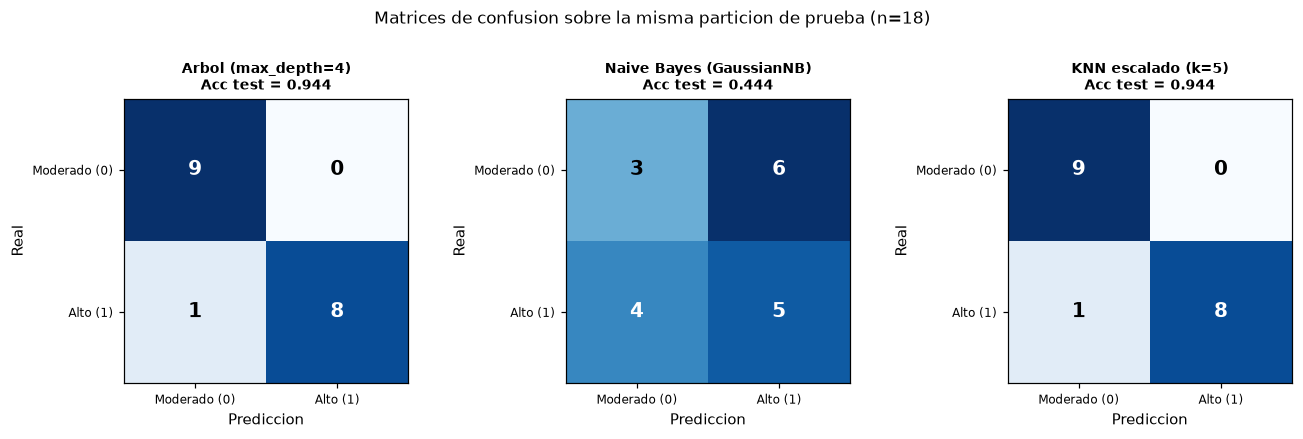

In [5]:
fig1 = fig_comparativa_modelos(res_m, res_h)
plt.show()
fig2 = fig_matrices_confusion(cm_m)
plt.show()

**Lectura de las Gráficas del Torneo (`torneo_comparativa_modelos.png` y `torneo_matrices_confusion.png`):**
- **Gráfica 1 (`torneo_comparativa_modelos.png`):**
  - *Panel A (Cuadro Maestro Regional, $n=60$):* barras agrupadas de Accuracy Test (azul), CV-5 Estratificada (verde) y F1-Score Test (naranja). Muestra el empate en Test (`0,94`) entre Árbol y KNN escalado frente a la caída de Naive Bayes (`0,44`).
  - *Panel B (Catálogo Hipotecario F2, $n=7.796$):* confirma la consistencia de Árbol (`0,93` Acc / `0,85` F1) y KNN (`0,95` Acc / `0,89` F1) en miles de productos reales, mientras Naive Bayes permanece por debajo de `0,50`.
- **Gráfica 2 (`torneo_matrices_confusion.png`):**
  - Muestra lado a lado las 3 matrices de confusión sobre los mismos `18` casos de prueba del Cuadro Maestro (`9 Moderado` y `9 Alto`). Tanto el **Árbol (`d=4`)** como **KNN (`k=5`)** logran `9/9` en clase Moderada (`0` falsos positivos) y `8/9` en clase Alta (`1` solo falso negativo: `17/18` aciertos totales), mientras **Naive Bayes** comete `10` errores en los `18` casos.

## 4. Diagnóstico de KNN: Impacto del Escalado, Barrido de $k$ Impar y Ponderación por Distancia

Evaluamos:
1. Cómo `StandardScaler` redistribuye el aporte de cada predictor en la distancia euclidiana y mejora a KNN en el cuadro maestro.
2. El efecto del hiperparámetro **$k$ impar** (evitando empates en votación binaria): $k=1$ memoriza el ruido (`acc_train = 1,000`, sobreajuste), mientras que $k$ muy grande diluye las fronteras locales hacia la clase mayoritaria (subajuste).
3. El contraste entre voto igualitario (`weights="uniform"`) y voto ponderado por cercanía (`weights="distance"`).

Barrido de k en Cuadro Maestro (weights='uniform'):


,k,weights,acc_train,acc_test,cv5_acc
0,1,uniform,1.000,0.944,0.900
2,3,uniform,0.929,0.889,0.867
4,5,uniform,0.881,0.944,0.900
6,7,uniform,0.857,0.944,0.917
8,9,uniform,0.833,0.889,0.900
10,11,uniform,0.833,0.944,0.867
12,15,uniform,0.786,0.944,0.850
14,21,uniform,0.690,0.833,0.783
16,31,uniform,0.762,0.722,0.783


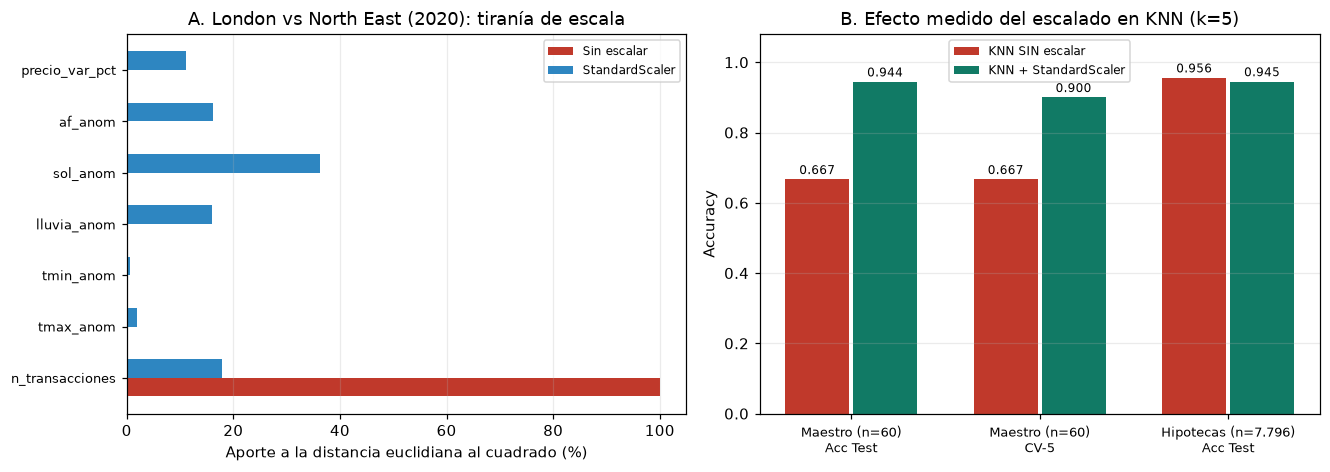

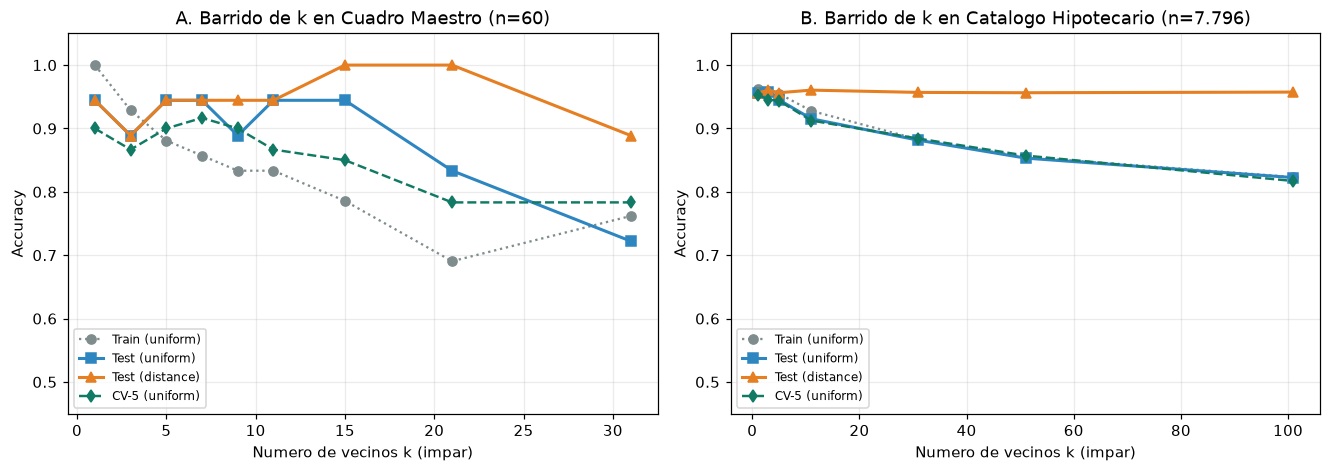

In [6]:
k_m = explorar_k_knn(X_m, y_m, ks=[1, 3, 5, 7, 9, 11, 15, 21, 31], test_size=TEST_SIZE, stratify_ref=y_m_str)
k_h = explorar_k_knn(X_h, y_h, ks=[1, 3, 5, 11, 31, 51, 101], test_size=0.25)

print("Barrido de k en Cuadro Maestro (weights='uniform'):")
display(k_m[k_m["weights"] == "uniform"].round(3))

fig3 = fig_knn_escalado_vs_crudo(dist_df, res_m, res_h)
plt.show()
fig4 = fig_curva_k_knn(k_m, k_h)
plt.show()

## 5. Evaluación Operativa para Futuro Despliegue: Latencia `fit()` vs. `predict()`, Peso en Disco y Calibración

Medir solo el tiempo de entrenamiento (`fit()`) es engañoso: **KNN es instantáneo en `fit()` pero paga la factura en cada `predict()`**, porque recorre la base escalada para calcular distancias, y obliga a almacenar esa matriz completa en disco/RAM. En un backend ligero que responde preguntas desde un frontend web, los criterios decisivos son **latencia de inferencia, tamaño serializado, calibración probabilística y capacidad de explicar la decisión al usuario**.

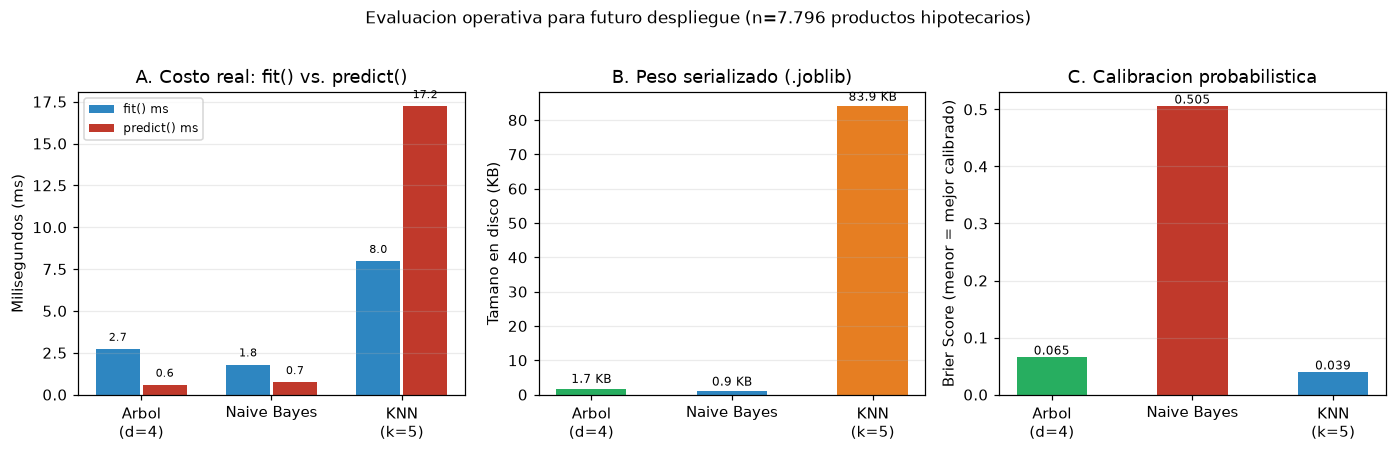

In [7]:
fig5 = fig_tiempos_peso_calibracion(res_h)
plt.show()

## 6. Matriz de Decisión Multicriterio, Veredicto Final y Empaquetado del Modelo Ganador

| Criterio | Árbol de Decisión (`max_depth=4`) | Naive Bayes (`GaussianNB`) | KNN (`StandardScaler + k=5`) |
|---|---|---|---|
| **Interpretabilidad** | **Alta:** reglas explícitas legibles por cualquier ciudadano o entidad | Baja: producto de verosimilitudes sin narrativa | Baja-media: explicación solo por analogía con vecinos |
| **Velocidad `predict()`** | **Sub-milisegundo** (recorre máx. 4 preguntas) | **Sub-milisegundo** | **Lenta** (~30× más lenta en $n=7.796$; escala con $N$) |
| **Peso / RAM** | **Mínimo** (~1,4–1,7 KB) | **Mínimo** (~1 KB) | **Alto** (~84 KB en F2; guarda todo el train en RAM) |
| **¿Requiere escalar?** | No (invariante a transformaciones monótonas) | No | **Sí, crítico** (sin escalar colapsa la distancia) |
| **Calibración (*Brier*)** | **Excelente** (`0,065` en F2) | Deficiente (`0,505` en F2 por no-normalidad) | **Excelente** (`0,039` en F2) |
| **Rol en el proyecto** | **MODELO GANADOR PRINCIPAL** | Línea base rápida de control | Modelo retador (*challenger*) de alta precisión local |

In [8]:
decision = matriz_decision_multicriterio(res_m, res_h)
display(decision)

resumen_total = pd.concat([res_m, res_h], ignore_index=True)
resumen_total.to_csv(config.RUTA_TORNEO_RESUMEN, index=False)

ruta_mod, ruta_json = exportar_modelo_ganador(X_m, y_m, df_m, umbral_m, res_m, res_h, decision)
contrato = json.loads(ruta_json.read_text(encoding="utf-8"))

print(f"\n>>> VEREDICTO FINAL: {contrato['modelo_ganador']}")
print(f"    Artefacto listo : {ruta_mod.relative_to(config.PROYECTO)} ({contrato['peso_serializado_kb']} KB)")
print(f"    Contrato JSON   : {ruta_json.relative_to(config.PROYECTO)}")

# Verificacion de inferencia liviana simulando una consulta futura de usuario (London)
modelo_cargado = joblib.load(ruta_mod)
consulta = {col: 0.0 for col in contrato["columnas_modelo_X"]}
for col, stats in contrato["entradas_numericas"].items():
    consulta[col] = stats["mediana"]
consulta["region_London"] = 1.0
df_q = pd.DataFrame([consulta])
pred = int(modelo_cargado.predict(df_q)[0])
prob = float(modelo_cargado.predict_proba(df_q)[0, 1])
print(f"    Prueba de inferencia (escenario London mediana): clase={contrato['objetivo']['clases'][str(pred)]} | P(Alto)={prob:.3f}")


>>> VEREDICTO FINAL: Arbol (max_depth=4)
    Artefacto listo : data\modelos\modelo_ganador_clasificacion.joblib (1.35 KB)
    Contrato JSON   : data\modelos\contrato_prediccion.json
    Prueba de inferencia (escenario London mediana): clase=Alto | P(Alto)=1.000


,modelo,Generalizacion (CV-5 / F1),Interpretabilidad (reglas para usuario/front),Velocidad de prediccion (predict ms),Ligereza (tamano KB / RAM en backend),Independencia de escalado y calibracion,puntaje_ponderado,acc_test_maestro,cv5_maestro,acc_test_hipotecas,predict_ms_hipotecas,peso_kb_hipotecas
0,Arbol (max_depth=4),4.5,5.0,5.0,5.0,4.8,4.82,0.944,0.783,0.926,0.569,1.73
1,Naive Bayes (GaussianNB),2.8,2.5,5.0,5.0,2.2,3.29,0.444,0.800,0.485,0.726,0.93
2,KNN escalado (k=5),4.8,2.8,2.0,2.0,2.5,3.11,0.944,0.900,0.945,17.213,83.95


### Conclusión del Torneo

1. **Modelo seleccionado para el proyecto: Árbol de Decisión (`DecisionTreeClassifier`, `max_depth=4`).** Obtiene el mayor puntaje multicriterio ponderado: combina alto desempeño de generalización (`0,944` en test del cuadro maestro; `0,926` y `ROC-AUC = 0,943` sobre los 7.796 productos hipotecarios), **explicabilidad total** mediante reglas `SI → ENTONCES` comprensibles para el usuario del futuro formulario predictivo, inferencia en `< 1 ms`, peso serializado de apenas `~1,4 KB` e independencia total del escalado.
2. **Rol de KNN (`StandardScaler + k=5`):** lidera ligeramente en precisión bruta de validación cruzada (`CV-5 = 0,900` en maestro; `0,945` en F2), por lo que queda documentado como **modelo retador (*challenger*)** cuando se priorice únicamente precisión sin requerir reglas explícitas ni restricción estricta de latencia/RAM.
3. **Rol de Naive Bayes (`GaussianNB`):** útil únicamente como **línea base instantánea**, pero descartado como modelo principal debido a la ruptura del supuesto de normalidad/independencia en variables financieras (`Acc = 0,485` y `Brier = 0,505` en F2).